In [1]:
#Task 1: Load Zomato restaurants data and inspect it
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

zo = pd.read_csv("zomato_restaurants_data.csv")

print(zo.head())
print()
zo.info()
print()
print(zo.describe())

           name   location       cuisine    cost  rating  votes
0  Restaurant 1   Alkapuri  North Indian   391.0     3.7   1528
1  Restaurant 2      Vasna  North Indian  5028.0     3.2   1000
2  Restaurant 3      Akota       Biryani   358.0     3.2    251
3  Restaurant 4  Fatehgunj       Chinese     NaN     3.4   1926
4  Restaurant 5  Manjalpur  South Indian   200.0     3.6    395

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      800 non-null    str    
 1   location  800 non-null    str    
 2   cuisine   800 non-null    str    
 3   cost      765 non-null    float64
 4   rating    770 non-null    float64
 5   votes     800 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 37.6 KB

              cost      rating        votes
count   765.000000  770.000000   800.000000
mean    504.249673    3.556104  1441.326250
std     503.941061

Missing values:
cost      35
rating    30
dtype: int64


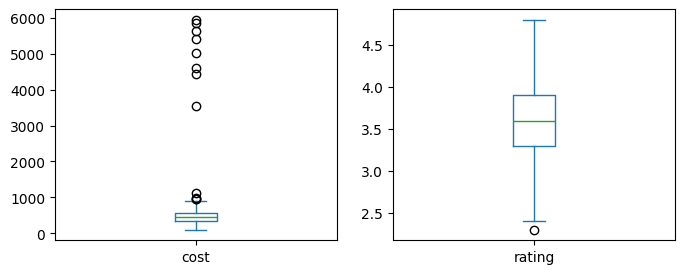

cost -> limits: 8.5 to 908.5 , outliers capped: 13
rating -> limits: 2.55 to 4.55 , outliers capped: 18

Missing values after:
cost      0
rating    0
dtype: int64


In [2]:
#Task 2: Missing values and outliers in cost and rating
print("Missing values:")
print(zo[["cost", "rating"]].isnull().sum())

# boxplots before handling
zo[["cost", "rating"]].plot(kind="box", subplots=True, figsize=(8, 3))
plt.show()

# fill missing values with the median
zo["cost"] = zo["cost"].fillna(zo["cost"].median())
zo["rating"] = zo["rating"].fillna(zo["rating"].median())

# outliers with the IQR method: values outside the limits are capped to the limits
for col in ["cost", "rating"]:
    q1 = zo[col].quantile(0.25)
    q3 = zo[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = ((zo[col] < low) | (zo[col] > high)).sum()
    zo[col] = zo[col].clip(low, high)
    print(col, "-> limits:", round(low, 2), "to", round(high, 2), ", outliers capped:", n_out)

print("\nMissing values after:")
print(zo[["cost", "rating"]].isnull().sum())

In [3]:
#Task 3: Encode cuisine and location, scale cost and rating
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ohe = OneHotEncoder(sparse_output=False)
enc = ohe.fit_transform(zo[["cuisine", "location"]])
enc_df = pd.DataFrame(enc, columns=ohe.get_feature_names_out(["cuisine", "location"]), index=zo.index)

sc = StandardScaler()
scaled = pd.DataFrame(sc.fit_transform(zo[["cost", "rating"]]), columns=["cost_scaled", "rating_scaled"], index=zo.index)

data = pd.concat([scaled, enc_df], axis=1)
print("Shape:", data.shape)
print(data.head())

Shape: (800, 20)
   cost_scaled  rating_scaled  cuisine_Biryani  cuisine_Cafe  cuisine_Chinese  \
0    -0.404851       0.344889              0.0           0.0              0.0   
1     2.625849      -0.864187              0.0           0.0              0.0   
2    -0.598113      -0.864187              1.0           0.0              0.0   
3    -0.041753      -0.380557              0.0           0.0              1.0   
4    -1.523428       0.103074              0.0           0.0              0.0   

   cuisine_Desserts  cuisine_Fast Food  cuisine_Gujarati  cuisine_Italian  \
0               0.0                0.0               0.0              0.0   
1               0.0                0.0               0.0              0.0   
2               0.0                0.0               0.0              0.0   
3               0.0                0.0               0.0              0.0   
4               0.0                0.0               0.0              0.0   

   cuisine_North Indian  cuisine_

In [4]:
#Task 4: Logistic Regression vs Random Forest to predict rating above 4.0
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

y = (zo["rating"] > 4.0).astype(int)
# rating is used to make the target, so it is removed from the features (otherwise the model would just read the answer)
X = data.drop(columns="rating_scaled")

xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

lr = LogisticRegression(max_iter=1000)
lr.fit(xtr, ytr)
rf = RandomForestClassifier(n_estimators=100, random_state=1)
rf.fit(xtr, ytr)

auc_lr = roc_auc_score(yte, lr.predict_proba(xte)[:, 1])
auc_rf = roc_auc_score(yte, rf.predict_proba(xte)[:, 1])
print("Logistic Regression ROC-AUC:", round(auc_lr, 3))
print("Random Forest ROC-AUC:", round(auc_rf, 3))

if auc_lr > auc_rf:
    print("Logistic Regression performed better")
else:
    print("Random Forest performed better")

Logistic Regression ROC-AUC: 0.715
Random Forest ROC-AUC: 0.573
Logistic Regression performed better


In [5]:
#Task 5: SMOTE and GridSearchCV for Random Forest
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV

print("Rating > 4.0:", int(ytr.sum()), " Rating <= 4.0:", int((ytr == 0).sum()), "(in the training set)")

xs, ys = SMOTE(random_state=1).fit_resample(xtr, ytr)
print("After SMOTE -> rating > 4.0:", int(ys.sum()), " rating <= 4.0:", int((ys == 0).sum()))

# SMOTE is inside the pipeline so it is applied only on the training part of every fold
pipe = ImbPipeline([("smote", SMOTE(random_state=1)), ("rf", RandomForestClassifier(random_state=1))])
grid = {"rf__n_estimators": [50, 100, 200], "rf__max_depth": [3, 5, 10, None]}

gs = GridSearchCV(pipe, grid, cv=5, scoring="roc_auc")
gs.fit(xtr, ytr)

print("\nBest parameters:", gs.best_params_)
print("Best cross-validation ROC-AUC:", round(gs.best_score_, 3))
print("Test ROC-AUC:", round(roc_auc_score(yte, gs.predict_proba(xte)[:, 1]), 3))

Rating > 4.0: 76  Rating <= 4.0: 564 (in the training set)
After SMOTE -> rating > 4.0: 564  rating <= 4.0: 564



Best parameters: {'rf__max_depth': 5, 'rf__n_estimators': 100}
Best cross-validation ROC-AUC: 0.678
Test ROC-AUC: 0.691
